<img src="./logo_UNSAM.jpg" align="right" width="150" /> 

#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº7
#### Florencia Vanella

# Consigna
##### Usando el archivo ecg.mat que contiene un registro electrocardiográfico (ECG) registrado durante una prueba de esfuerzo, junto con una serie de variables descriptas a continuación. Diseñe y aplique los filtros digitales necesarios para mitigar las siguientes fuentes de contaminación:


##### - Ruido causado por el movimiento de los electrodos (Alta frecuencia).
##### - Ruido muscular (Alta frecuencia).
##### - Movimiento de la línea de base del ECG, inducido en parte por la respiración (Baja frecuencia).

##### a) Establezca una plantilla de diseño para los filtros digitales que necesitará para que la señal de ECG se asemeje a los latidos promedio en cuanto a  suavidad de los trazos y nivel isoeléctrico nulo.

##### b) ¿Cómo obtuvo dichos valores? Describa el procedimiento para establecer los valores de la plantilla.


In [1]:
#%% ................... Inicialización y Carga de Datos ...................
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import scipy.signal as sig
from matplotlib.patches import Rectangle

# Cargar el archivo ECG_TP4.mat y definir la frecuencia de muestreo primero
fs_ecg = 1000.0  # Frecuencia de muestreo en Hz
mat_data = loadmat('ECG_TP4.mat')
ecg_one_lead = mat_data['ecg_lead'].flatten()
qrs_detections = mat_data['qrs_detections'].flatten()

print(f"Señal de ECG cargada con éxito. Muestras totales: {len(ecg_one_lead)}")

wp = 35.0  # Frecuencia de paso [Hz]
ws = 50.0  # Frecuencia de rechazo [Hz]
Gpass = 3  # Atenuación máxima en banda de paso [dB]
Gstop = 40 # Atenuación mínima en banda de rechazo [dB]

ripple = Gpass
att = Gstop

delta_w = 5.0

nyq_frec = fs_ecg / 2
ripple_db = 1        
atenuacion = 40  

# Plantilla
ws1 = wp 
wp1 = wp
wp2 = wp + delta_w
ws2 = wp + delta_w

frecs = np.array([0.0, ws1, wp1, wp2, ws2, nyq_frec]) / nyq_frec
gains = np.array([-atenuacion, -atenuacion, -ripple_db, -ripple_db, -atenuacion, -atenuacion])
gains = 10**(gains/20)


Señal de ECG cargada con éxito. Muestras totales: 1129116


Los valores de la plantilla de diseño del filtro se determinan analizando el contenido espectral de la señal de ECG, estimado en la TS5. 
Una frecuencia de paso wp = 35hz, porque ahí es donde vive la información más importante del ECG, especialmente el complejo QRS. Si se fija por debajo, se corre el riesgo de recortar partes clave de la señal, y lo que buscamos es que el latido pase entero, sin deformarse, para que el trazo quede suave.
Una frecuencia de rechazo ws = 50hz. Elegir una transición tan estrecha nos permite separar bien la señal útil del ruido sin necesidad de usar filtros de órdenes muy elevados que compliquen la implementación práctica.
En la banda de paso adoptamos un margen estándar de $3\text{ dB}$ (con un ripple de $1\text{ dB}$) para tolerar pequeñas variaciones de amplitud sin alterar la forma de las ondas del ECG. Por otro lado, en la banda de rechazo exigimos una atenuación de al menos $40\text{ dB}$ a partir de  los $50\text{ Hz}$ —lo que reduce el ruido unas 100 veces ($10^{40/20} = 100$) — 

##### c) Diseñe al menos dos filtros FIR y dos IIR para su comparación. Verifique que la respuesta en frecuencia responda a la plantilla de diseño.

Los filtros FIR son sistemas LIT (Lineales e Invariantes en el Tiempo) cuya respuesta al impulso ante una entrada delta tiene una duración finita. Se implementan mediante estructuras no recursivas, lo que significa que la salida en un instante dado depende únicamente de la combinación lineal de la entrada actual y de un número finito de entradas pasadas.

El algoritmo de cuadrados mínimos (ls) es una técnica estadística que se utiliza para encontrar la mejor aproximación de un conjunto de datos minimizando la suma de los cuadrados de las diferencias entre los valores observados y los valores predichos por el modelo. 

El algoritmo de Parks-McClellan (remez) es una herramienta poderosa utilizada para diseñar filtros FIR óptimos en términos de la minimización del error máximo en las bandas de frecuencia de interés. La fundamentación matemática de este algoritmo se basa en el método de la alternancia de Remez, y una búsqueda iterativa de las frecuencias extremas que acotan la señal de error.

Por otro lado, las ventanas Hann y Hamming truncan la respuesta al impulso ideal para suavizar el corte y mitigar el fenómeno de Gibbs. Mientras que la ventana de Hann ofrece un equilibrio general entre el ancho del lóbulo principal y la atenuación de los secundarios, la ventana de Hamming modifica ligeramente sus coeficientes para suprimir con mayor fuerza el primer lóbulo lateral, logrando una mayor atenuación inicial cerca de la frecuencia de corte a cambio de una tasa de caída posterior un poco más suave. 

Los IIR son sistemas cuya respuesta al impulso se extiende teóricamente hasta el infinito. Se implementan mediante estructuras recursivas, lo que implica que la salida actual depende no solo de las entradas actuales y pasadas, sino también de las salidas anteriores (realimentación).

El filtro Butterworth prioriza la maxima planicidad, es decir, una respuesta completamente monótona y sin rizado en la banda de paso, entregando una caída suave sin ondulaciones. 

El Chebyshev Tipo II (cheby2) mejora la selectividad permitiendo rizado únicamente en la banda de rechazo, lo que mantiene la banda de paso estrictamente plana y protege la amplitud de las ondas del ECG. 

Finalmente, el filtro Cauer (cauer) utiliza funciones racionales para admitir rizado en ambas bandas, logrando la transición más abrupta y eficiente posible entre el paso y el rechazo para un orden dado, a costa de una fase fuertemente no lineal.


In [8]:

# 1. DISEÑO DE FILTROS IIR y FIR

# IIR (SOS)
sos_cheby2 = sig.iirdesign(wp, ws, Gpass, Gstop, ftype='cheby2', fs=fs_ecg, output='sos')
sos_cauer  = sig.iirdesign(wp, ws, Gpass, Gstop, ftype='cauer', fs=fs_ecg, output='sos')
sos_butt   = sig.iirdesign(wp, ws, Gpass, Gstop, ftype='butter', fs=fs_ecg, output='sos')

# FIR
num_taps = 201
bands = [0.0, wp, wp + delta_w, fs_ecg/2]
desired_remez = [1.0, 0.0]
desired_firls = [1.0, 1.0, 0.0, 0.0]

b_hamming = sig.firwin2(num_taps, [0.0, wp, wp + delta_w, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window='hamming', fs=fs_ecg)
b_hann    = sig.firwin2(num_taps, [0.0, wp, wp + delta_w, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window='hann', fs=fs_ecg)
b_ls      = sig.firls(num_taps, bands, desired_firls, fs=fs_ecg)
b_remez   = sig.remez(num_taps, bands, desired_remez, fs=fs_ecg)


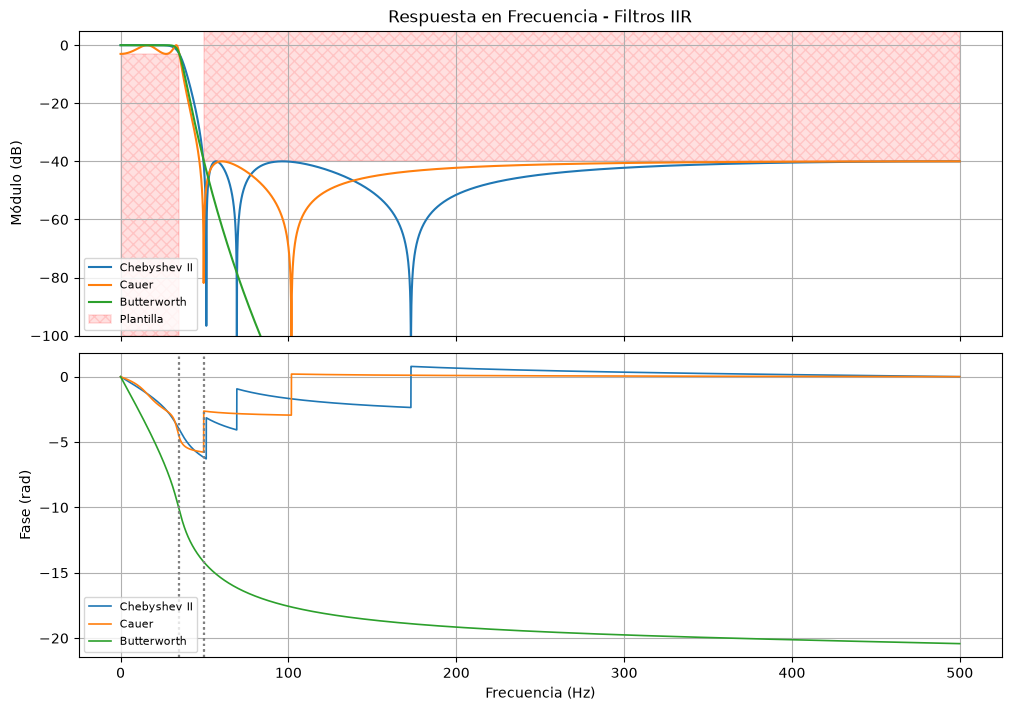

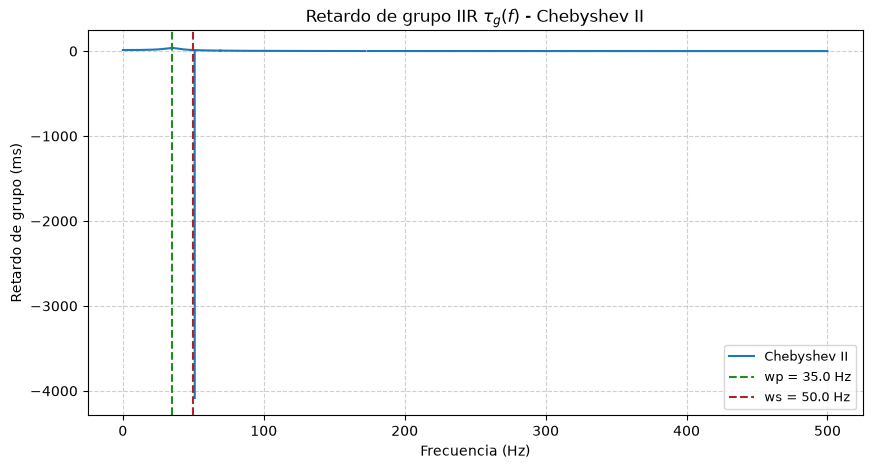

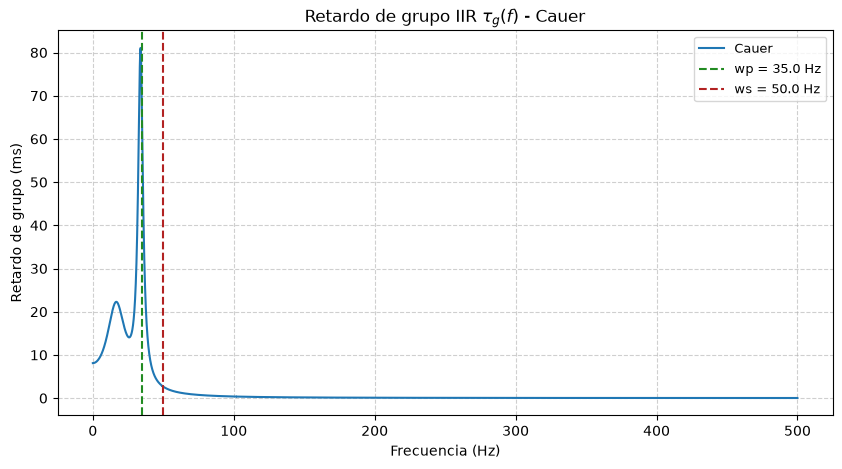

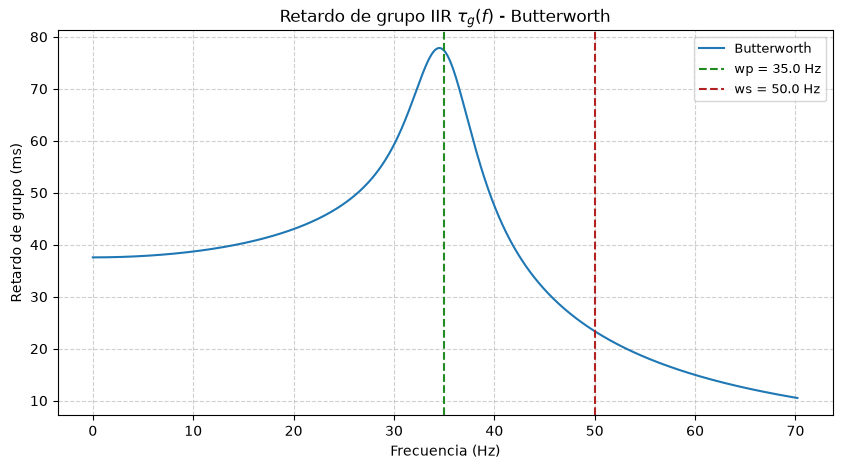

In [18]:
# 2. ANÁLISIS IIR (Módulo, Fase y Retardo)

y_min, y_max = -100, 5

def calc_resp_iir(sos, leg_str, fig_n_axes):
    f, h = sig.sosfreqz(sos, worN=8192, fs=fs_ecg)
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))
    
    omega = 2 * np.pi * f  
    retardo_s = -np.gradient(fase_rad, omega)
    retardo_ms = retardo_s * 1000  
    
    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_ms_plot = np.where(valido, retardo_ms, np.nan)
    
    (fig, (ax_mod, ax_fase)) = fig_n_axes
    
    # Módulo IIR (Dibuja la curva y le guarda el label)
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en Frecuencia - Filtros IIR")
    ax_mod.grid(True)
    
    # Fase IIR (Dibuja la curva y le guarda el label)
    ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
    ax_fase.axvline(wp, color="gray", linestyle=":")
    ax_fase.axvline(ws, color="gray", linestyle=":")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)
    
    # Retardo de Grupo IIR (Ventana separada)
    plt.figure(figsize=(10, 5))
    plt.plot(f, retardo_ms_plot, label=leg_str, linewidth=1.5)
    plt.axvline(wp, color="forestgreen", linestyle="--", label=f"wp = {wp} Hz")
    plt.axvline(ws, color="firebrick", linestyle="--", label=f"ws = {ws} Hz")
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Retardo de grupo (ms)")
    plt.title(f"Retardo de grupo IIR $\\tau_g(f)$ - {leg_str}")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(loc="best", fontsize=9)

# 1. Crear la figura principal de Módulo y Fase
fig_iir_axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)

# 2. Ejecutar la función para los tres filtros IIR
calc_resp_iir(sos_cheby2, 'Chebyshev II', fig_iir_axes)
calc_resp_iir(sos_cauer, 'Cauer', fig_iir_axes)
calc_resp_iir(sos_butt, 'Butterworth', fig_iir_axes)

# 3. Recuperar ejes y agregar Plantilla visual sobre el módulo IIR
(fig, (ax_mod, ax_fase)) = fig_iir_axes
rect_pasante = Rectangle((0, y_min), wp, -Gpass - y_min, facecolor="red", alpha=0.12, edgecolor="red", hatch="xxx", linewidth=1.2, label='Plantilla')
ax_mod.add_patch(rect_pasante)
rect_rechazo = Rectangle((ws, -Gstop), fs_ecg / 2 - ws, y_max + Gstop, facecolor="red", alpha=0.12, edgecolor="red", hatch="xxx", linewidth=1.2)
ax_mod.add_patch(rect_rechazo)

ax_mod.legend(loc="lower left", fontsize=8)  # Muestra los nombres de los filtros + la plantilla
ax_fase.legend(loc="lower left", fontsize=8)  # Muestra los nombres de los filtros en la fase



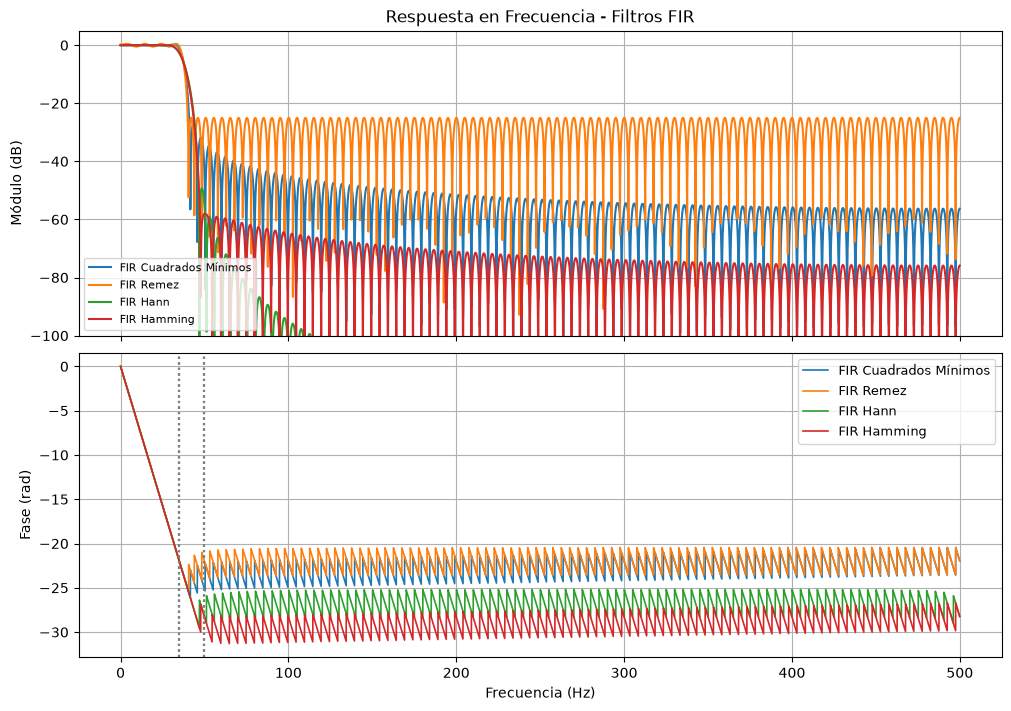

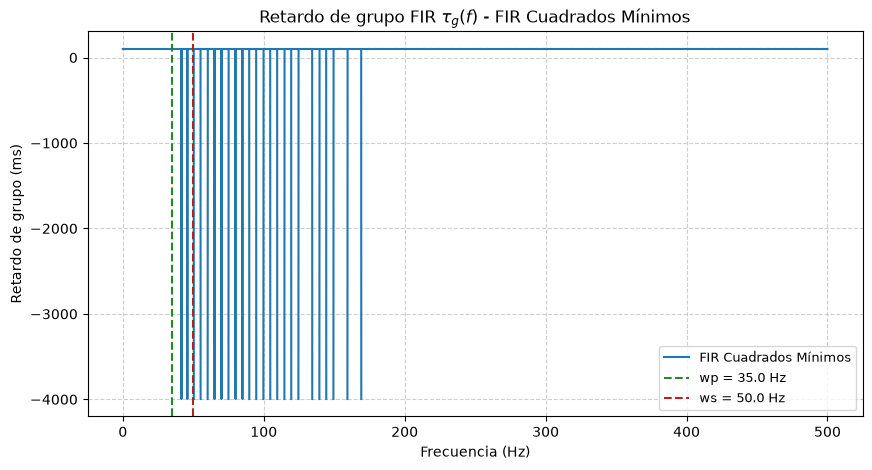

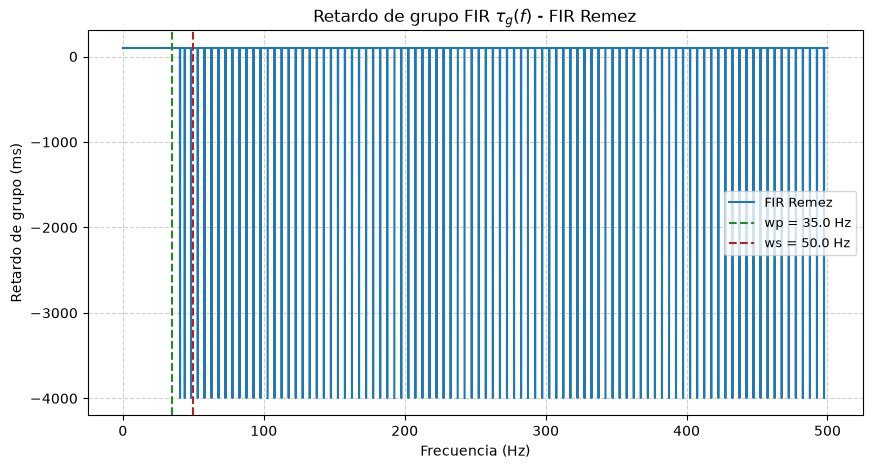

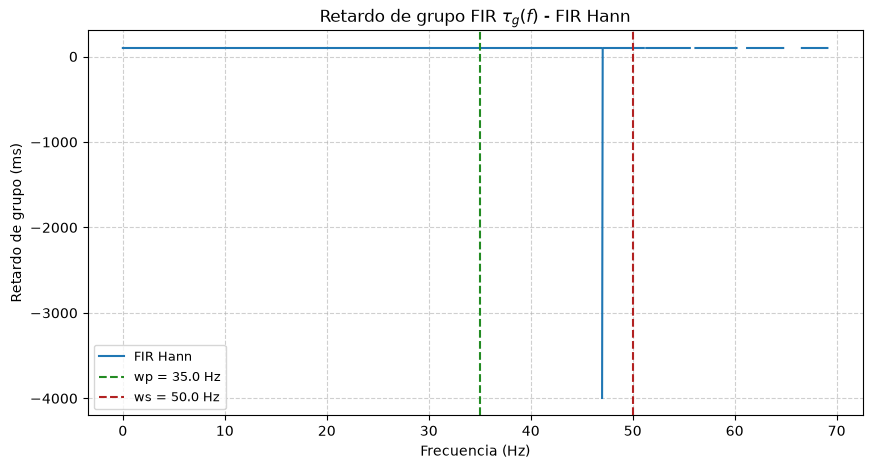

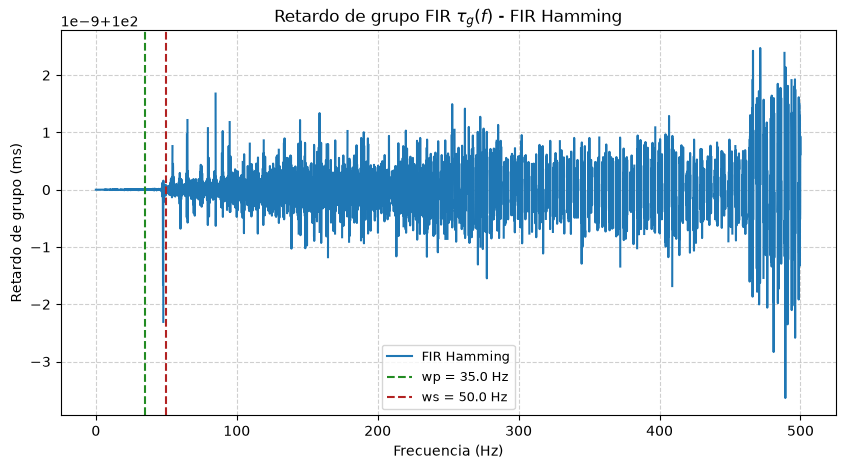

In [17]:
#%% ANÁLISIS DE MÓDULO, FASE Y RETARDO: FILTROS FIR 

def calc_resp_fir(b, leg_str, fig_n_axes):
    f, h = sig.freqz(b, 1.0, worN=8192, fs=fs_ecg)
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))
    
    omega = 2 * np.pi * f  
    retardo_s = -np.gradient(fase_rad, omega)
    retardo_ms = retardo_s * 1000  
    
    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_ms_plot = np.where(valido, retardo_ms, np.nan)
    
    (fig, (ax_mod, ax_fase)) = fig_n_axes
    
    # Módulo FIR 
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en Frecuencia - Filtros FIR")
    ax_mod.grid(True)
    
    # Fase FIR (Linealidad) 
    ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
    ax_fase.axvline(wp, color="gray", linestyle=":")
    ax_fase.axvline(ws, color="gray", linestyle=":")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)
    
    # Retardo de Grupo FIR (Ventana separada para cada uno)
    plt.figure(figsize=(10, 5))
    plt.plot(f, retardo_ms_plot, label=leg_str, linewidth=1.5)
    plt.axvline(wp, color="forestgreen", linestyle="--", label=f"wp = {wp} Hz")
    plt.axvline(ws, color="firebrick", linestyle="--", label=f"ws = {ws} Hz")
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Retardo de grupo (ms)")
    plt.title(f"Retardo de grupo FIR $\\tau_g(f)$ - {leg_str}")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(loc="best", fontsize=9)


# Ejecución FIR
fig_fir, (ax_mod, ax_fase) = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)
fig_fir_axes = (fig_fir, (ax_mod, ax_fase))

calc_resp_fir(b_ls, 'FIR Cuadrados Mínimos', fig_fir_axes)
calc_resp_fir(b_remez, 'FIR Remez', fig_fir_axes)
calc_resp_fir(b_hann, 'FIR Hann', fig_fir_axes)
calc_resp_fir(b_hamming, 'FIR Hamming', fig_fir_axes)

# Agregar las leyendas a los ejes del gráfico conjunto
ax_mod.legend(loc="lower left", fontsize=8)
ax_fase.legend(loc="best", fontsize=9)


##### d)  Evalúe el rendimiento de los filtros que haya diseñado:

- Verifique que filtra las señales interferentes.
- Verifique que es inocuo en las zonas donde no hay interferentes.

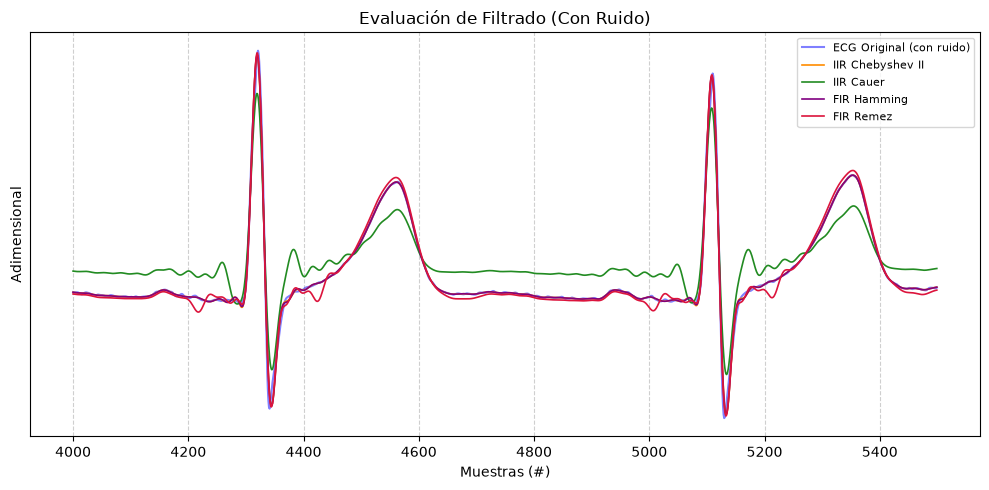

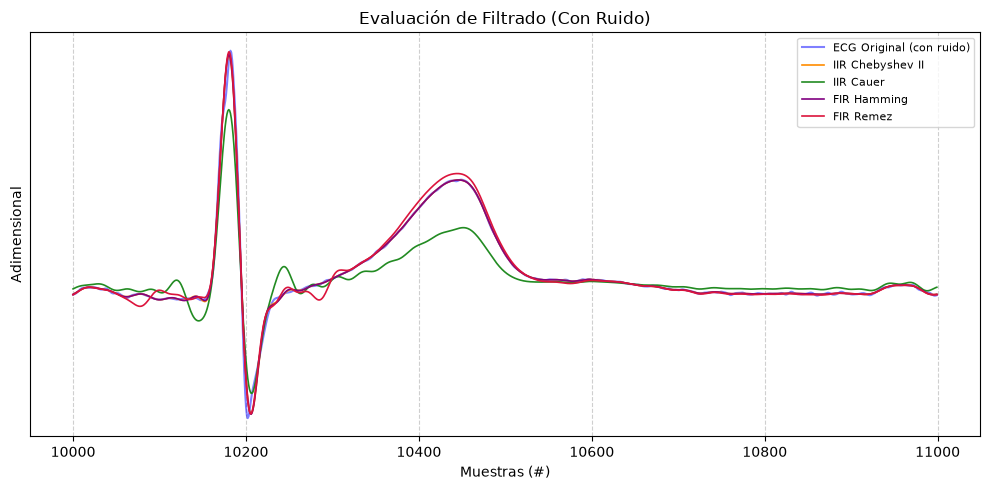

In [25]:
#%% APLICACIÓN DE FILTROS A LA SEÑAL (Fase Cero) 
ecg_filt_cheby2 = sig.sosfiltfilt(sos_cheby2, ecg_one_lead)
ecg_filt_cauer  = sig.sosfiltfilt(sos_cauer, ecg_one_lead)
ecg_filt_butt  = sig.sosfiltfilt(sos_butt, ecg_one_lead)

ecg_fir_hamming = sig.filtfilt(b_hamming, 1.0, ecg_one_lead)
ecg_fir_hann    = sig.filtfilt(b_hann, 1.0, ecg_one_lead)
ecg_fir_ls      = sig.filtfilt(b_ls, 1.0, ecg_one_lead)
ecg_fir_remez   = sig.filtfilt(b_remez, 1.0, ecg_one_lead)

#%% EVALUACIÓN EN REGIONES CON RUIDO
cant_muestras = ecg_one_lead.shape[0]

regs_interes_ruido = (
    [4000, 5500], 
    [10e3, 11e3], 
)

for ii in regs_interes_ruido:
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='int')
    
    plt.figure(figsize=(10, 5))
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG Original (con ruido)', linewidth=1.5, alpha=0.5, color='blue')
    
    plt.plot(zoom_region, ecg_filt_cheby2[zoom_region], label='IIR Chebyshev II', linewidth=1.2, color='darkorange')
    plt.plot(zoom_region, ecg_filt_cauer[zoom_region], label='IIR Cauer', linewidth=1.2, color='forestgreen')
    plt.plot(zoom_region, ecg_fir_hamming[zoom_region], label='FIR Hamming', linewidth=1.2, color='purple')
    plt.plot(zoom_region, ecg_fir_remez[zoom_region], label='FIR Remez', linewidth=1.2, color='crimson')
    
    plt.title('Evaluación de Filtrado (Con Ruido)')
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend(loc='upper right', fontsize=8)
    axes_hdl.set_yticks(())
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()

Se observa que los filtros cumplen satisfactoriamente con la supresión de las interferencias. Las respuestas de Chebyshev II, Hamming y Remez muestran una alta fidelidad respecto al ECG original, preservando de forma adecuada la morfología en las zonas limpias sin alterar las amplitudes.

Por otro lado, en el gráfico se evidencia que el diseño Cauer es muy eficiente para atenuar, pero introduce un leve error de amplitud (ripple) en las zonas de menor frecuencia debido a las características de su aproximación elíptica, lo que genera una pequeña distorsión visual en comparación con los demás filtros.

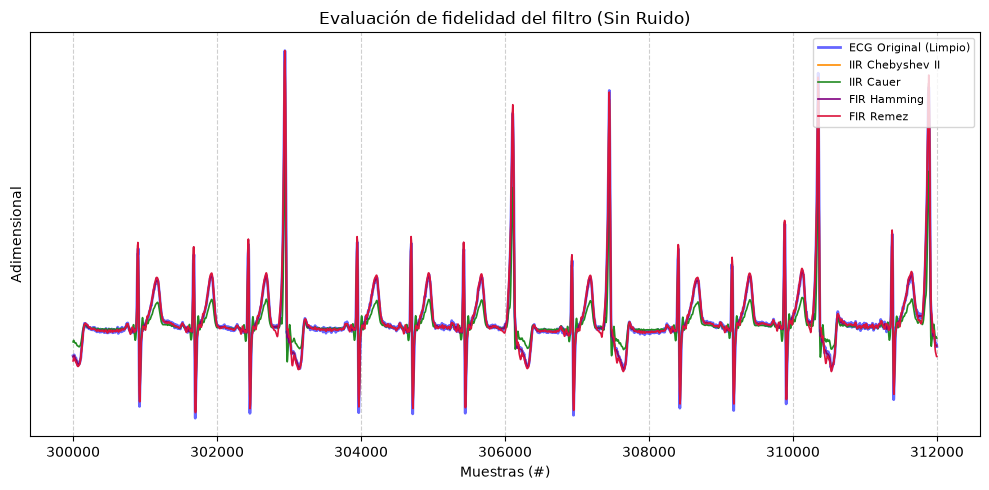

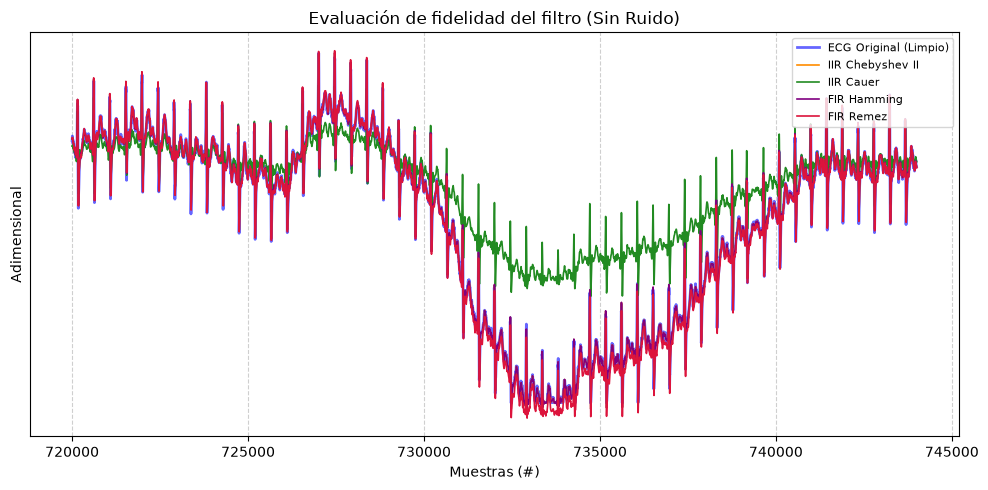

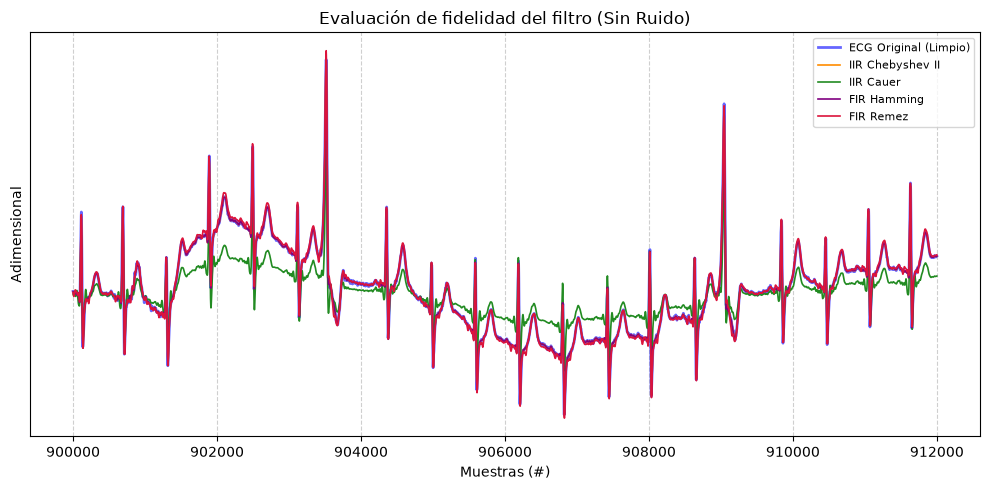

In [26]:
#%% EVALUACIÓN EN REGIONES SIN RUIDO 
regs_interes_limpias = (
    np.array([5, 5.2]) * 60 * fs_ecg, # minutos a muestras
    np.array([12, 12.4]) * 60 * fs_ecg, # minutos a muestras
    np.array([15, 15.2]) * 60 * fs_ecg, # minutos a muestras
)

for ii in regs_interes_limpias:
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='int')
    
    plt.figure(figsize=(10, 5))
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG Original (Limpio)', linewidth=2.0, alpha=0.6, color='blue')
    
    plt.plot(zoom_region, ecg_filt_cheby2[zoom_region], label='IIR Chebyshev II', linewidth=1.2, color='darkorange')
    plt.plot(zoom_region, ecg_filt_cauer[zoom_region], label='IIR Cauer', linewidth=1.2, color='forestgreen')
    plt.plot(zoom_region, ecg_fir_hamming[zoom_region], label='FIR Hamming', linewidth=1.2, color='purple')
    plt.plot(zoom_region, ecg_fir_remez[zoom_region], label='FIR Remez', linewidth=1.2, color='crimson')
    
    plt.title('Evaluación de fidelidad del filtro (Sin Ruido)')
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend(loc='upper right', fontsize=8)
    axes_hdl.set_yticks(())
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()


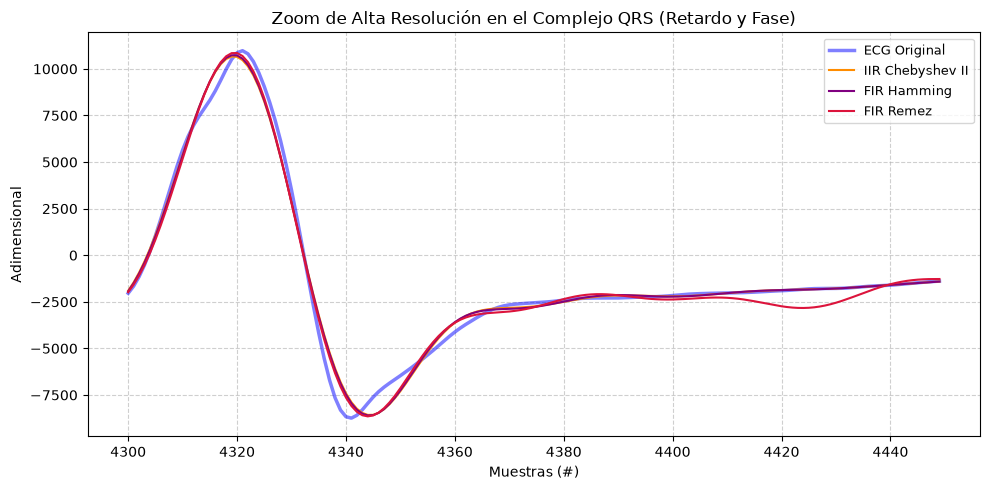

In [27]:
#%% 
# ZOOM EN EL COMPLEJO QRS

inicio_qrs = 4300
fin_qrs    = 4450
zoom_qrs   = np.arange(inicio_qrs, fin_qrs)

plt.figure(figsize=(10, 5))

# Señal original de referencia
plt.plot(zoom_qrs, ecg_one_lead[zoom_qrs], label='ECG Original', linewidth=2.5, alpha=0.5, color='blue')

# Filtros a comparar en el detalle
plt.plot(zoom_qrs, ecg_filt_cheby2[zoom_qrs], label='IIR Chebyshev II', linewidth=1.5, color='darkorange')
plt.plot(zoom_qrs, ecg_fir_hamming[zoom_qrs], label='FIR Hamming', linewidth=1.5, color='purple')
plt.plot(zoom_qrs, ecg_fir_remez[zoom_qrs], label='FIR Remez', linewidth=1.5, color='crimson')

plt.title('Zoom de Alta Resolución en el Complejo QRS (Retardo y Fase)')
plt.ylabel('Adimensional')
plt.xlabel('Muestras (#)')
plt.legend(loc='upper right', fontsize=9)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

En términos de amplitud y forma en la banda de paso, ambos tipos de filtros (IIR Y FIR) se comportan de manera idéntica frente a un transitorio rápido como el complejo QRS.  Se observa que las señales filtradas sufren un retardo de grupo debido al procesamiento y al orden de los filtros (necesario para lograr la selectividad en frecuencia). Este corrimiento es la prueba gráfica de la demora que introduce el filtrado digital en el dominio del tiempo.